In [1]:
import pandas as pd
import numpy as np

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

In [6]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [7]:
import joblib

In [8]:
import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [9]:
#Load WineQT.csv
df = pd.read_csv("WineQT.csv")


In [10]:
df.head()

,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,white,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,white,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,white,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [11]:
df.tail()

,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
6492,red,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
6493,red,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,NaN,11.2,6
6494,red,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
6495,red,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5
6496,red,6.0,0.310,0.47,3.6,0.067,18.0,42.0,0.99549,3.39,0.66,11.0,6


In [12]:
df.sample(5, random_state=42)

,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
3103,white,7.0,0.25,0.45,2.3,0.045,40.0,118.0,0.99064,3.16,0.48,11.9,7
1419,white,7.6,0.14,0.74,1.6,0.040,27.0,103.0,0.99160,3.07,0.40,10.8,7
4761,white,6.2,0.15,0.27,11.0,0.035,46.0,116.0,0.99602,3.12,0.38,9.1,6
4690,white,6.7,0.16,0.32,12.5,0.035,18.0,156.0,0.99666,2.88,0.36,9.0,6
4032,white,6.8,0.27,0.22,17.8,0.034,16.0,116.0,0.99890,3.07,0.53,9.2,5


In [13]:
df.shape[0]

6497

In [14]:
df.shape[1]

13

In [15]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 6497
Number of columns: 13


In [16]:
print(df.columns.tolist())

['type', 'fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']


Basic Data Inspection

In [17]:
print("Shape of dataset:", df.shape)

Shape of dataset: (6497, 13)


In [18]:
for column in df.columns:
    print(column)

type
fixed acidity
volatile acidity
citric acid
residual sugar
chlorides
free sulfur dioxide
total sulfur dioxide
density
pH
sulphates
alcohol
quality


In [19]:
df.dtypes

type                     object
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   type                  6497 non-null   object 
 1   fixed acidity         6487 non-null   float64
 2   volatile acidity      6489 non-null   float64
 3   citric acid           6494 non-null   float64
 4   residual sugar        6495 non-null   float64
 5   chlorides             6495 non-null   float64
 6   free sulfur dioxide   6497 non-null   float64
 7   total sulfur dioxide  6497 non-null   float64
 8   density               6497 non-null   float64
 9   pH                    6488 non-null   float64
 10  sulphates             6493 non-null   float64
 11  alcohol               6497 non-null   float64
 12  quality               6497 non-null   int64  
dtypes: float64(11), int64(1), object(1)
memory usage: 660.0+ KB


In [22]:
df.nunique()

type                      2
fixed acidity           106
volatile acidity        187
citric acid              89
residual sugar          316
chlorides               214
free sulfur dioxide     135
total sulfur dioxide    276
density                 998
pH                      108
sulphates               111
alcohol                 111
quality                   7
dtype: int64

In [23]:
print(df["quality"].value_counts().sort_index())

quality
3      30
4     216
5    2138
6    2836
7    1079
8     193
9       5
Name: count, dtype: int64


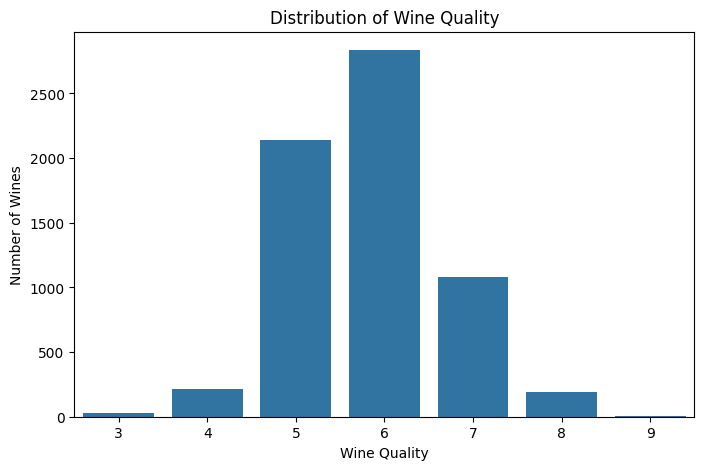

In [24]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="quality",
    order=sorted(df["quality"].unique())
)

plt.title("Distribution of Wine Quality")
plt.xlabel("Wine Quality")
plt.ylabel("Number of Wines")
plt.show()

In [25]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,6487.000000,6489.000000,6494.000000,6495.000000,6495.000000,6497.000000,6497.000000,6497.000000,6488.000000,6493.000000,6497.000000,6497.000000
mean,7.216579,0.339691,0.318722,5.444326,0.056042,30.525319,115.744574,0.994697,3.218395,0.531215,10.491801,5.818378
std,1.296750,0.164649,0.145265,4.758125,0.035036,17.749400,56.521855,0.002999,0.160748,0.148814,1.192712,0.873255
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000,5.000000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000,6.000000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000,6.000000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000,9.000000


In [26]:
print(df.isnull().sum())

type                     0
fixed acidity           10
volatile acidity         8
citric acid              3
residual sugar           2
chlorides                2
free sulfur dioxide      0
total sulfur dioxide     0
density                  0
pH                       9
sulphates                4
alcohol                  0
quality                  0
dtype: int64


In [27]:
missing_values = df.isnull().sum()

print(missing_values[missing_values > 0])

fixed acidity       10
volatile acidity     8
citric acid          3
residual sugar       2
chlorides            2
pH                   9
sulphates            4
dtype: int64


In [28]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 1168


Data Cleaning

In [29]:
data=df.copy()

In [31]:
print(data.columns.tolist())

['type', 'fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']


In [32]:
print(data.isnull().sum())
numeric_columns = data.select_dtypes(include=np.number).columns

for column in numeric_columns:
    data[column] = data[column].fillna(data[column].median())

type                     0
fixed acidity           10
volatile acidity         8
citric acid              3
residual sugar           2
chlorides                2
free sulfur dioxide      0
total sulfur dioxide     0
density                  0
pH                       9
sulphates                4
alcohol                  0
quality                  0
dtype: int64


In [33]:
print(data.isnull().sum())

type                    0
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64


In [34]:
print("Duplicates before:", data.duplicated().sum())

data = data.drop_duplicates()

print("Duplicates after:", data.duplicated().sum())

Duplicates before: 1168
Duplicates after: 0


In [35]:
print(data.dtypes)

type                     object
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object


In [36]:
print(data.describe().T)

                       count        mean        std      min      25%  \
fixed acidity         5329.0    7.216166   1.317988  3.80000   6.4000   
volatile acidity      5329.0    0.344042   0.168115  0.08000   0.2300   
citric acid           5329.0    0.318733   0.147075  0.00000   0.2400   
residual sugar        5329.0    5.053068   4.503336  0.60000   1.8000   
chlorides             5329.0    0.056665   0.036838  0.00900   0.0380   
free sulfur dioxide   5329.0   30.060143  17.815588  1.00000  16.0000   
total sulfur dioxide  5329.0  114.189341  56.781422  6.00000  75.0000   
density               5329.0    0.994536   0.002966  0.98711   0.9922   
pH                    5329.0    3.224410   0.160141  2.72000   3.1100   
sulphates             5329.0    0.533250   0.149669  0.22000   0.4300   
alcohol               5329.0   10.548539   1.186134  8.00000   9.5000   
quality               5329.0    5.796022   0.879922  3.00000   5.0000   

                            50%        75%        

In [37]:
numeric_columns = data.select_dtypes(include=np.number).columns

for column in numeric_columns:
    print(
        column,
        "Minimum =", data[column].min(),
        "Maximum =", data[column].max()
    )

fixed acidity Minimum = 3.8 Maximum = 15.9
volatile acidity Minimum = 0.08 Maximum = 1.58
citric acid Minimum = 0.0 Maximum = 1.66
residual sugar Minimum = 0.6 Maximum = 65.8
chlorides Minimum = 0.009 Maximum = 0.611
free sulfur dioxide Minimum = 1.0 Maximum = 289.0
total sulfur dioxide Minimum = 6.0 Maximum = 440.0
density Minimum = 0.98711 Maximum = 1.03898
pH Minimum = 2.72 Maximum = 4.01
sulphates Minimum = 0.22 Maximum = 2.0
alcohol Minimum = 8.0 Maximum = 14.9
quality Minimum = 3 Maximum = 9


EDA

In [38]:
quality_counts = data["quality"].value_counts().sort_index()

print(quality_counts)

quality
3      30
4     206
5    1755
6    2327
7     857
8     149
9       5
Name: count, dtype: int64


In [39]:
print("Most common quality:")
print(quality_counts.idxmax(), "with", quality_counts.max(), "samples")

Most common quality:
6 with 2327 samples


In [40]:
print("Least common quality:")
print(quality_counts.idxmin(), "with", quality_counts.min(), "samples")

Least common quality:
9 with 5 samples


Quality Distribution Plot

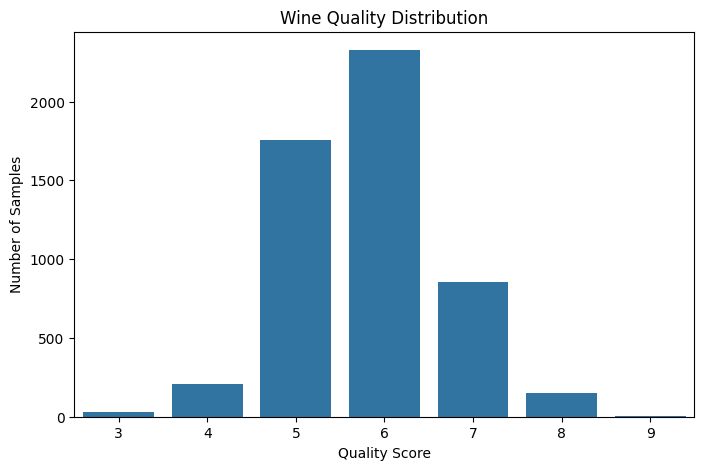

In [41]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=data,
    x="quality",
    order=sorted(data["quality"].unique())
)

plt.title("Wine Quality Distribution")
plt.xlabel("Quality Score")
plt.ylabel("Number of Samples")
plt.show()

Distribution of Numerical Features

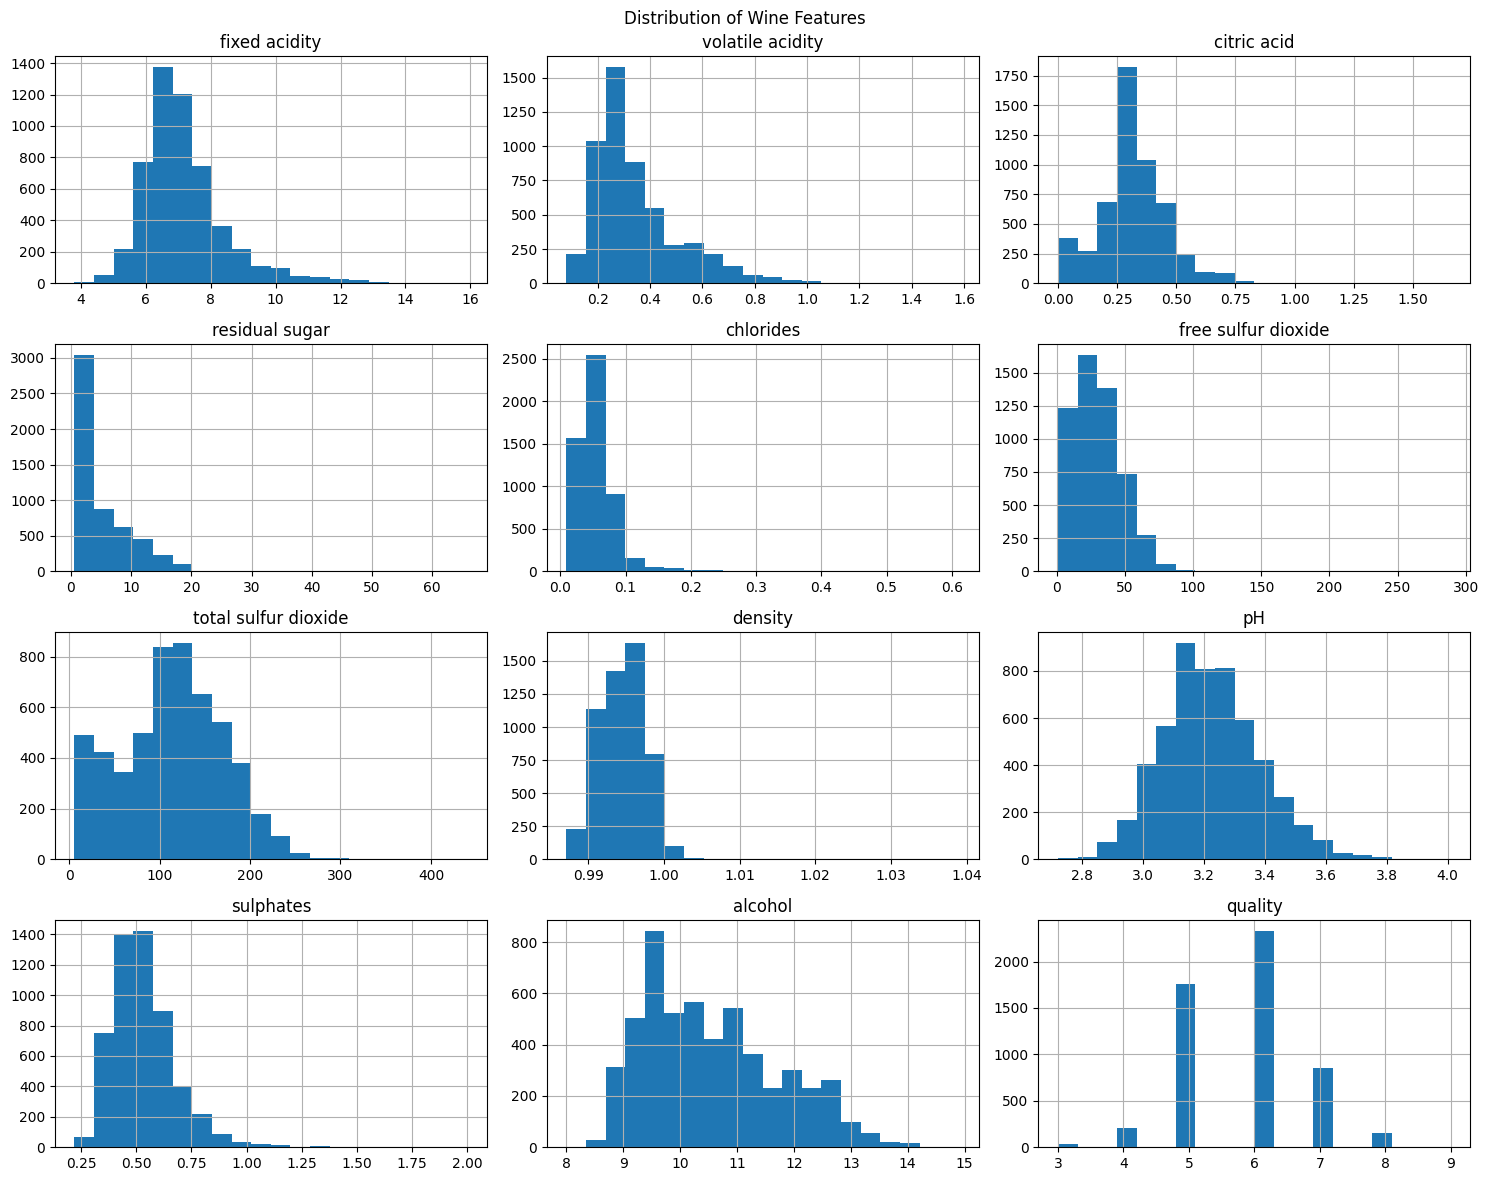

In [42]:
data.hist(
    figsize=(15, 12),
    bins=20
)

plt.suptitle("Distribution of Wine Features")
plt.tight_layout()
plt.show()

Alchohol vs Quality

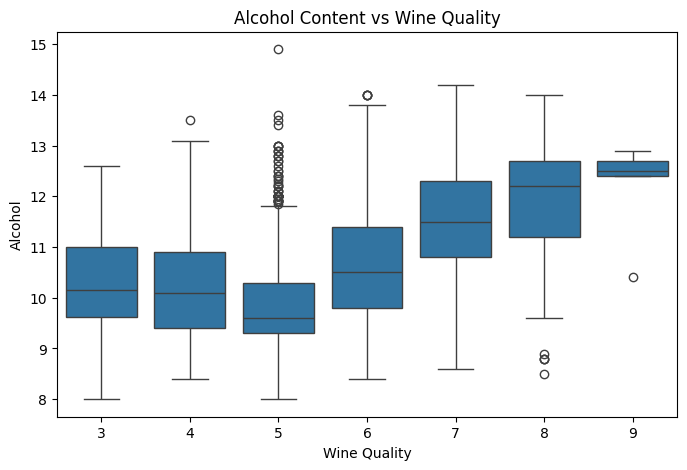

In [43]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=data,
    x="quality",
    y="alcohol"
)

plt.title("Alcohol Content vs Wine Quality")
plt.xlabel("Wine Quality")
plt.ylabel("Alcohol")
plt.show()

Volatile Acidity vs Quality

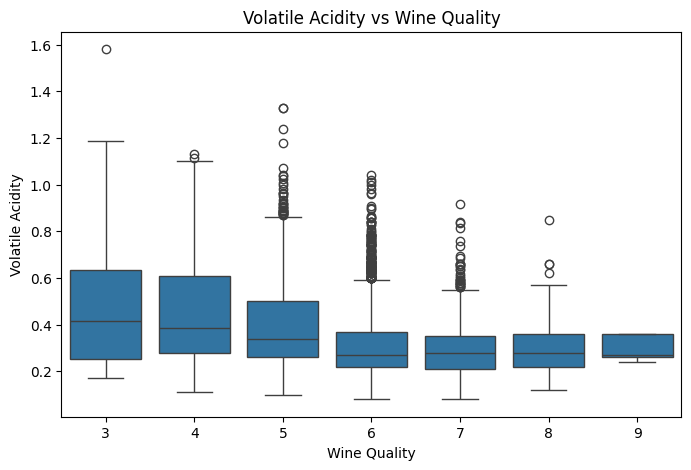

In [44]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=data,
    x="quality",
    y="volatile acidity"
)

plt.title("Volatile Acidity vs Wine Quality")
plt.xlabel("Wine Quality")
plt.ylabel("Volatile Acidity")
plt.show()

Sulphates vs Quality

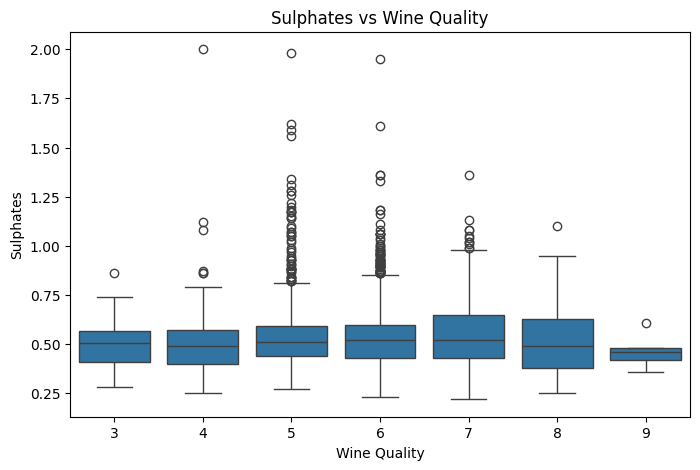

In [45]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=data,
    x="quality",
    y="sulphates"
)

plt.title("Sulphates vs Wine Quality")
plt.xlabel("Wine Quality")
plt.ylabel("Sulphates")
plt.show()

pH vs Quality

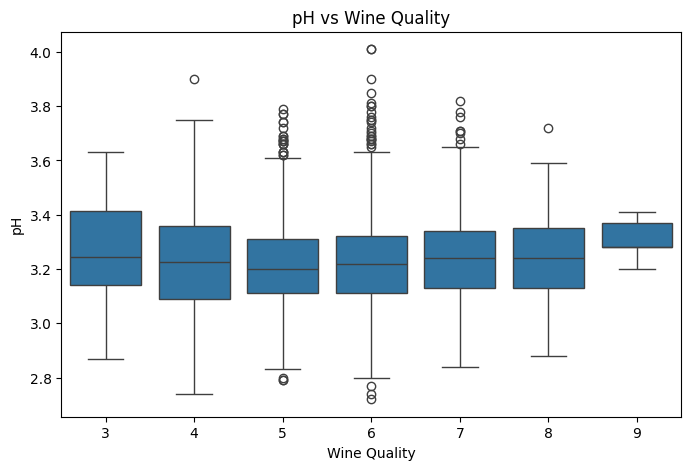

In [46]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=data,
    x="quality",
    y="pH"
)

plt.title("pH vs Wine Quality")
plt.xlabel("Wine Quality")
plt.ylabel("pH")
plt.show()

Citric Acid vs Quality

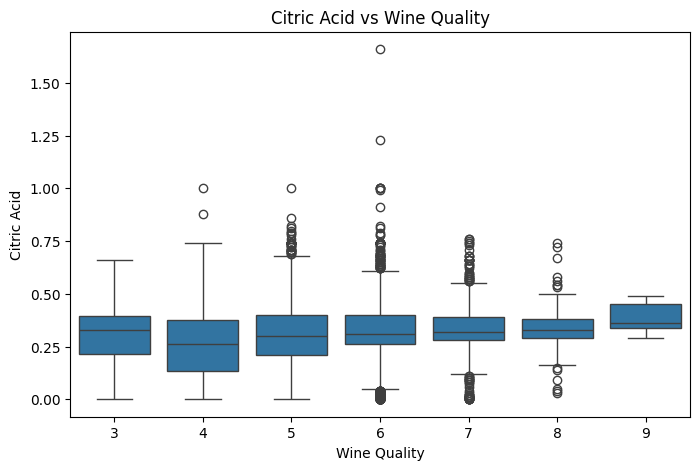

In [47]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=data,
    x="quality",
    y="citric acid"
)

plt.title("Citric Acid vs Wine Quality")
plt.xlabel("Wine Quality")
plt.ylabel("Citric Acid")
plt.show()

Dataset Outliers

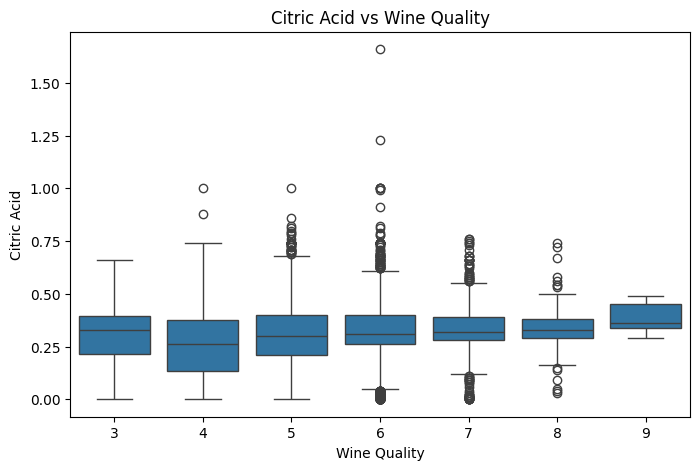

In [48]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=data,
    x="quality",
    y="citric acid"
)

plt.title("Citric Acid vs Wine Quality")
plt.xlabel("Wine Quality")
plt.ylabel("Citric Acid")
plt.show()

Correlation Analysis

Correlation Matrix

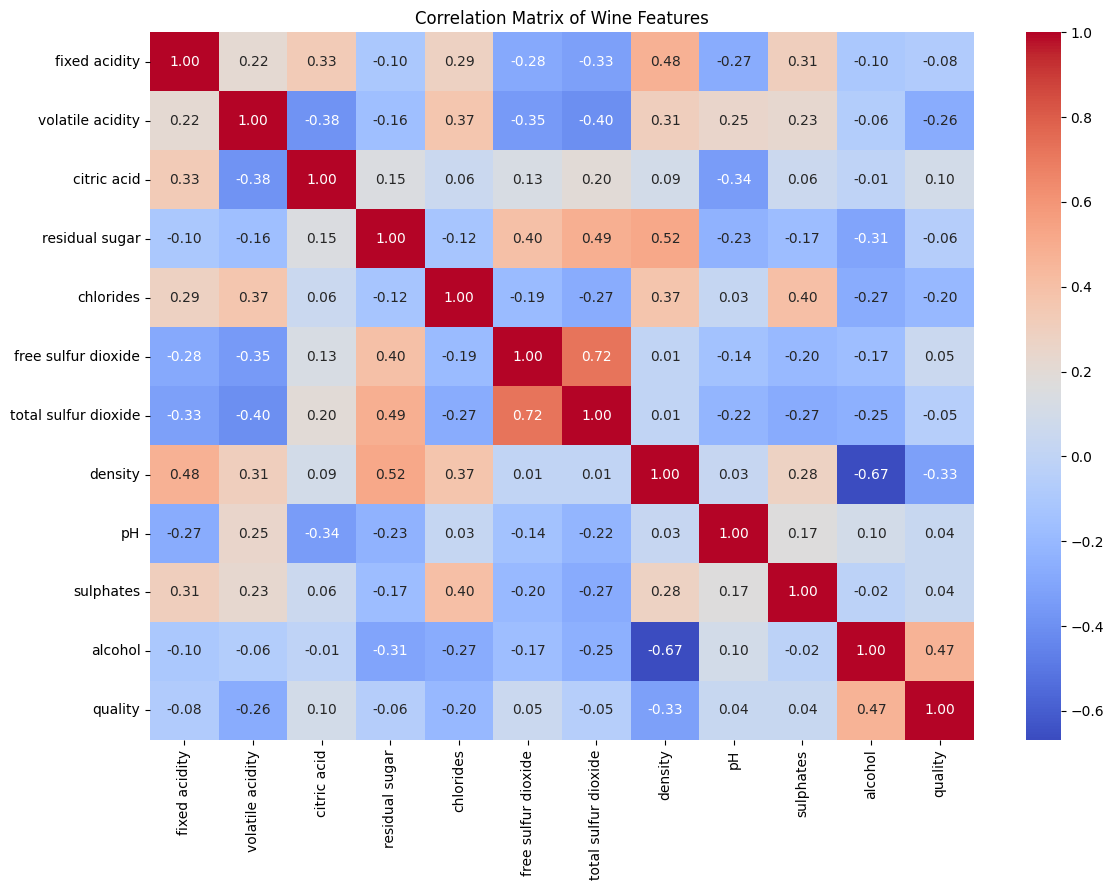

In [49]:
correlation = data.corr(numeric_only=True)

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Wine Features")
plt.tight_layout()
plt.show()

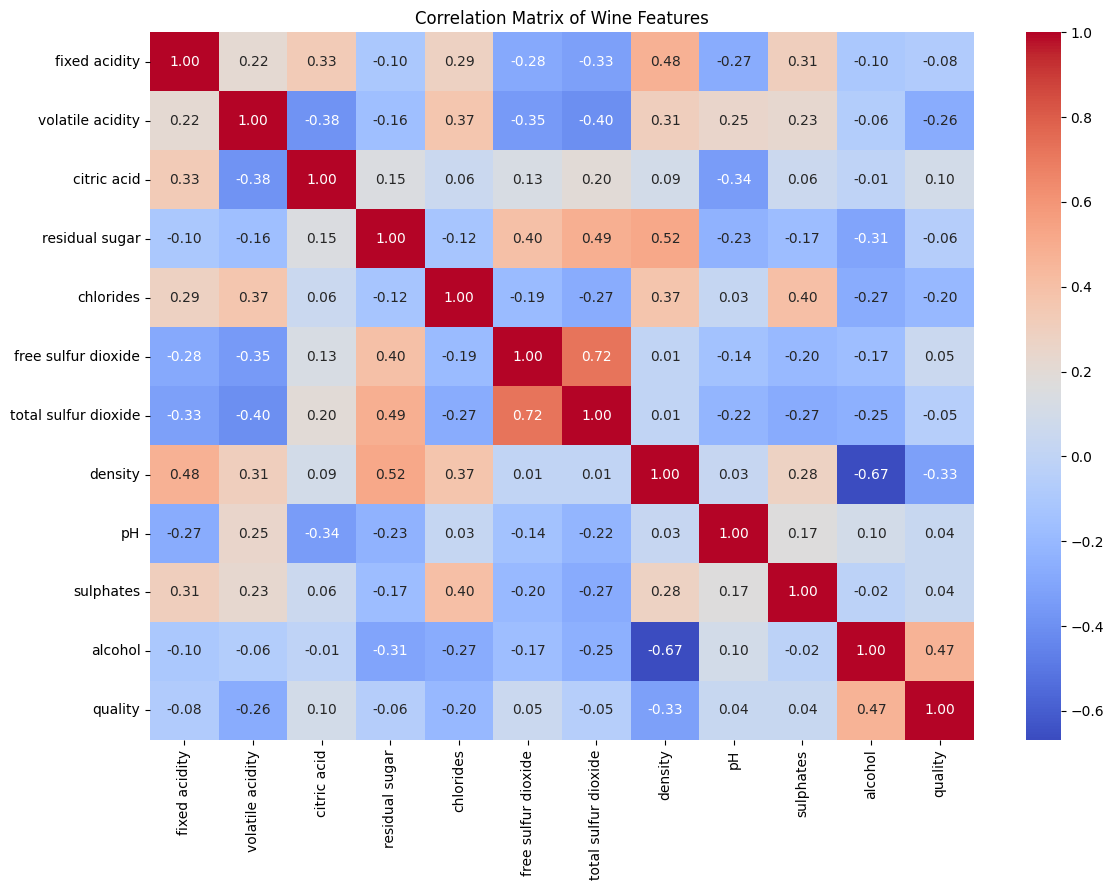

In [50]:
#Find correlation with a matrix and visualize it using a heatmap
correlation = data.corr(numeric_only=True)

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Wine Features")
plt.tight_layout()
plt.show()

In [52]:
quality_correlation = correlation["quality"].sort_values(
    ascending=False
)

print(quality_correlation)
print("Correlation with quality:")
print(quality_correlation)

quality                 1.000000
alcohol                 0.469555
citric acid             0.098769
free sulfur dioxide     0.054456
sulphates               0.041462
pH                      0.039937
total sulfur dioxide   -0.050387
residual sugar         -0.057414
fixed acidity          -0.080519
chlorides              -0.202226
volatile acidity       -0.264294
density                -0.326978
Name: quality, dtype: float64
Correlation with quality:
quality                 1.000000
alcohol                 0.469555
citric acid             0.098769
free sulfur dioxide     0.054456
sulphates               0.041462
pH                      0.039937
total sulfur dioxide   -0.050387
residual sugar         -0.057414
fixed acidity          -0.080519
chlorides              -0.202226
volatile acidity       -0.264294
density                -0.326978
Name: quality, dtype: float64


Feature and Target Separation

Seprate X and y

In [53]:
X = data.drop(columns=["quality"])
y = data["quality"]

In [55]:
print("Input features:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

Input features:
['type', 'fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']

Target:
quality


In [56]:
print("Does X contain quality?", "quality" in X.columns)
print("Does X contain Id?", "Id" in X.columns)

Does X contain quality? False
Does X contain Id? False


Train-Test Split

Split Dataset

In [58]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [59]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (4263, 12)
Testing data: (1066, 12)


In [61]:
print("Training class distribution:")
print(y_train.value_counts(normalize=True).sort_index())

print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True).sort_index())

Training class distribution:
quality
3    0.005630
4    0.038705
5    0.329346
6    0.436547
7    0.160920
8    0.027915
9    0.000938
Name: proportion, dtype: float64

Testing class distribution:
quality
3    0.005629
4    0.038462
5    0.329268
6    0.437148
7    0.160413
8    0.028143
9    0.000938
Name: proportion, dtype: float64


Feature Scaling 

Standard Scale

In [64]:
scaler = StandardScaler()

# 'type' is categorical (string), so drop it before scaling
X_train_scaled = scaler.fit_transform(X_train.drop(columns=["type"]))
X_test_scaled = scaler.transform(X_test.drop(columns=["type"]))


In [65]:
#Check Scaled data

print(X_train_scaled[:5])

[[-0.00859707  1.91583027 -2.14274974 -0.6317403   0.289799   -1.13915734
  -1.58260758  0.34487316  1.19671886  1.24629739  0.47237817]
 [-0.70227494 -0.56195234  0.82266059 -0.74150854 -0.86754597  0.33064524
   0.03396191 -1.74584443 -0.28814252 -0.8962975   1.65695082]
 [-0.16274771 -0.97491611  0.35089076 -0.78541583 -0.36778337 -0.79997213
  -0.17689498 -0.8058578  -0.28814252 -0.2267366   0.21854117]
 [-0.85642557 -0.97491611  0.41828645 -0.60978665 -0.63081631 -0.1216017
  -0.05389513 -1.65552543 -0.41188097 -0.29369269  1.57233849]
 [-0.70227494 -0.85692646 -0.5252532  -0.74150854 -0.13105371  0.33064524
   0.36781865 -0.27732439  3.54774937  0.84456085  0.21854117]]


Model Training

Logistic regrestion

In [66]:
logistic_model = LogisticRegression(
    max_iter=5000,
    random_state=42
)

logistic_model.fit(
    X_train_scaled,
    y_train
)

logistic_pred = logistic_model.predict(X_test_scaled)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [70]:
#Random Forest
rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42
)

rf_model.fit(
    X_train.drop(columns=["type"]),
    y_train
)

rf_pred = rf_model.predict(X_test.drop(columns=["type"]))

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [71]:
#Suport Vector Machine 
svm_model = SVC(
    probability=True,
    random_state=42
)

svm_model.fit(
    X_train_scaled,
    y_train
)

svm_pred = svm_model.predict(X_test_scaled)

print("SVM trained successfully!")

SVM trained successfully!


In [72]:
#K-Nearest Neighbors
knn_model = KNeighborsClassifier(
    n_neighbors=5
)

knn_model.fit(
    X_train_scaled,
    y_train
)

knn_pred = knn_model.predict(X_test_scaled)

print("KNN trained successfully!")

KNN trained successfully!


Model Evaluation

In [73]:
#Create Evaluation function
def evaluate_model(model_name, y_true, y_pred):
    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    }

In [74]:
#Evaluate all models
results = []

results.append(
    evaluate_model(
        "Logistic Regression",
        y_test,
        logistic_pred
    )
)

results.append(
    evaluate_model(
        "Random Forest",
        y_test,
        rf_pred
    )
)

results.append(
    evaluate_model(
        "SVM",
        y_test,
        svm_pred
    )
)

results.append(
    evaluate_model(
        "KNN",
        y_test,
        knn_pred
    )
)

In [78]:
results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.551595,0.505530,0.551595,0.521108
1,Random Forest,0.583490,0.576103,0.583490,0.562362
2,SVM,0.580675,0.533618,0.580675,0.543204
3,KNN,0.519700,0.497783,0.519700,0.506150


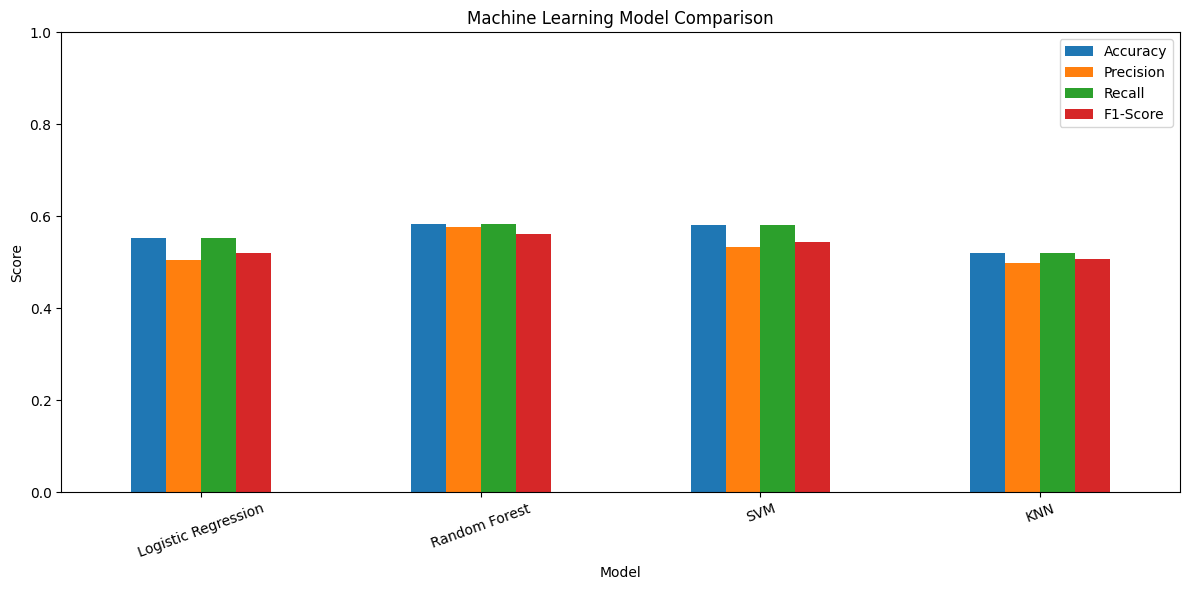

In [79]:
#Model Comparison Graph
results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-Score"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Machine Learning Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

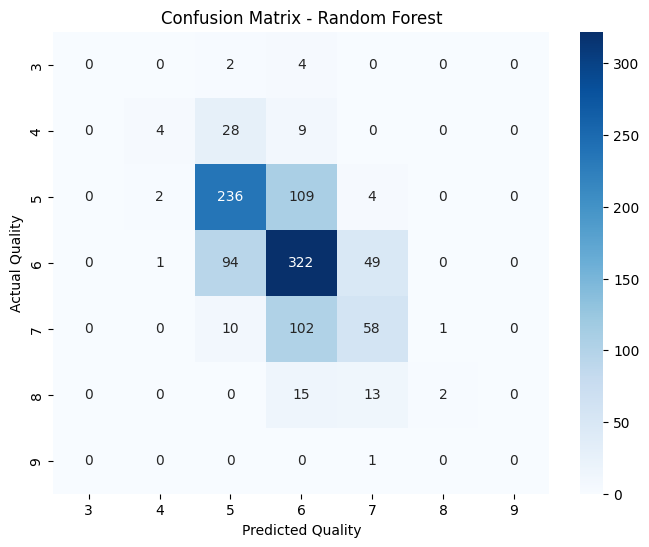

In [80]:
#Confusion Matrix
cm = confusion_matrix(
    y_test,
    rf_pred,
    labels=sorted(y.unique())
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted Quality")
plt.ylabel("Actual Quality")
plt.show()

In [81]:
predictions = {
    "Logistic Regression": logistic_pred,
    "Random Forest": rf_pred,
    "SVM": svm_pred,
    "KNN": knn_pred,
}

best_model_name = results_df.loc[results_df["F1-Score"].idxmax(), "Model"]
best_pred = predictions[best_model_name]

print("Best model:", best_model_name)

Best model: Random Forest


In [82]:
#Detailed Classification Report
print(
    classification_report(
        y_test,
        best_pred,
        zero_division=0
    )
)

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         6
           4       0.57      0.10      0.17        41
           5       0.64      0.67      0.65       351
           6       0.57      0.69      0.63       466
           7       0.46      0.34      0.39       171
           8       0.67      0.07      0.12        30
           9       0.00      0.00      0.00         1

    accuracy                           0.58      1066
   macro avg       0.42      0.27      0.28      1066
weighted avg       0.58      0.58      0.56      1066



Feature Importance

In [84]:
feature_importance = pd.DataFrame({
    "Feature": X_train.drop(columns=["type"]).columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
10,alcohol,0.125326
7,density,0.100087
1,volatile acidity,0.098800
6,total sulfur dioxide,0.091293
5,free sulfur dioxide,0.088418
4,chlorides,0.087849
9,sulphates,0.086936
8,pH,0.083626
3,residual sugar,0.082712
2,citric acid,0.078565


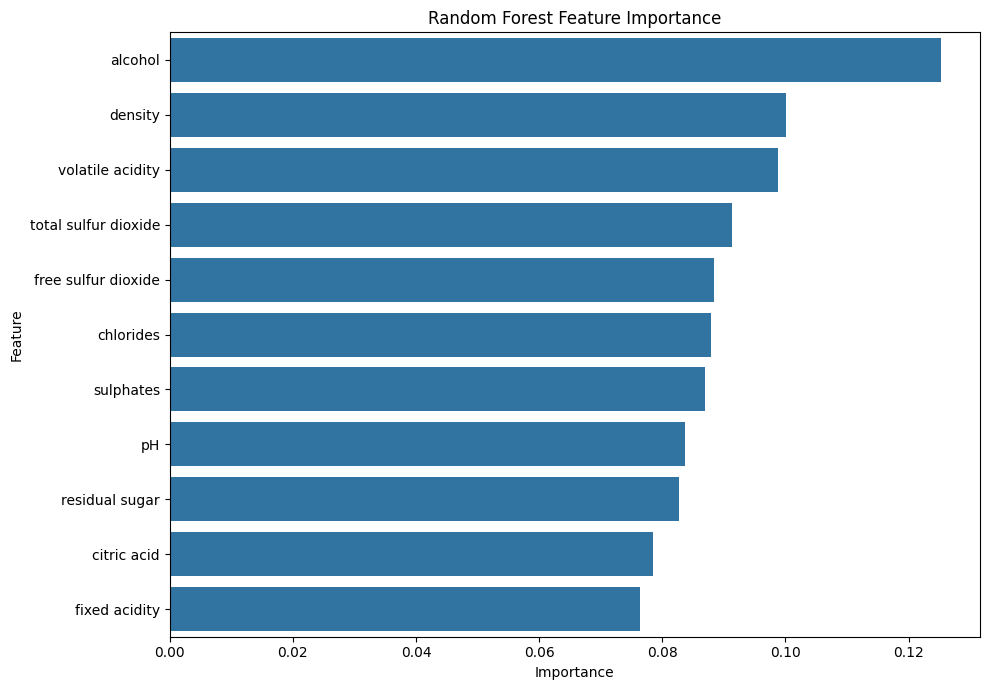

In [85]:
#Plot Feature Importance
plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [86]:
most_important_feature = feature_importance.iloc[0]

print("Most important feature:")
print(most_important_feature)

Most important feature:
Feature        alcohol
Importance    0.125326
Name: 10, dtype: object


Model Improvement

In [87]:
original_accuracy = accuracy_score(
    y_test,
    rf_pred
)

print("Original Accuracy:", original_accuracy)

Original Accuracy: 0.5834896810506567


In [90]:
improved_rf = RandomForestClassifier(
    n_estimators=500,
    max_depth=12,
    min_samples_split=4,
    min_samples_leaf=2,
    random_state=42
)

improved_rf.fit(
    X_train.drop(columns=["type"]),
    y_train
)

improved_pred = improved_rf.predict(X_test.drop(columns=["type"]))

improved_pred = improved_rf.predict(X_test.drop(columns=["type"]))

In [93]:
improved_accuracy = accuracy_score(
    y_test,
    improved_pred
)

improved_f1 = f1_score(
    y_test,
    improved_pred,
    average="weighted",
    zero_division=0
)

print("Original Accuracy:", original_accuracy)
print("Improved Accuracy:", improved_accuracy)
print("Improved F1 Score:", improved_f1)

Original Accuracy: 0.5834896810506567
Improved Accuracy: 0.5816135084427767
Improved F1 Score: 0.5558255482588684


Hyperparameter Tunning

In [94]:
#Define Parameter Grid 
param_grid = {
    "n_estimators": [200, 300, 500],
    "max_depth": [None, 10, 15, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt", "log2"]
}

In [95]:
#Create a Grid searchCV
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(
        random_state=42
    ),
    param_grid=param_grid,
    cv=5,
    scoring="f1_weighted",
    n_jobs=-1,
    verbose=1
)

In [97]:
#Tunning
# Random Forest requires numeric features; exclude the categorical "type" column.
grid_search.fit(
    X_train.drop(columns=["type"]),
    y_train
)

Fitting 5 folds for each of 96 candidates, totalling 480 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [None, 10, ...], 'max_features': ['sqrt', 'log2'], 'min_samples_leaf': [1, 2], 'min_samples_split': [2, 5], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_weighted'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold a

In [98]:
#Find Best Parameters
print("Best Parameters:")
print(grid_search.best_params_)

Best Parameters:
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 500}


In [99]:
#Best Cross validation
print("Best Cross-Validation Score: ", grid_search.best_score_ )

Best Cross-Validation Score:  0.5503817504851958


In [100]:
#Get tunned model
tuned_model = grid_search.best_estimator_

tuned_pred = tuned_model.predict(
    X_test.drop(columns=["type"])
)

print("Tuned model:", tuned_model)

Tuned model: RandomForestClassifier(min_samples_split=5, n_estimators=500, random_state=42)


In [101]:
#Final Text matrix
tuned_accuracy = accuracy_score(
    y_test,
    tuned_pred
)

tuned_precision = precision_score(
    y_test,
    tuned_pred,
    average="weighted",
    zero_division=0
)

tuned_recall = recall_score(
    y_test,
    tuned_pred,
    average="weighted",
    zero_division=0
)

tuned_f1 = f1_score(
    y_test,
    tuned_pred,
    average="weighted",
    zero_division=0
)

print("Tuned Model Performance")
print("-----------------------")
print("Accuracy :", tuned_accuracy)
print("Precision:", tuned_precision)
print("Recall   :", tuned_recall)
print("F1 Score :", tuned_f1)

Tuned Model Performance
-----------------------
Accuracy : 0.5872420262664165
Precision: 0.5882841835844301
Recall   : 0.5872420262664165
F1 Score : 0.563664012331648


In [102]:
#Compare Original vs Tuned Model
comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ],

    "Original Random Forest": [
        accuracy_score(y_test, rf_pred),
        precision_score(
            y_test,
            rf_pred,
            average="weighted",
            zero_division=0
        ),
        recall_score(
            y_test,
            rf_pred,
            average="weighted",
            zero_division=0
        ),
        f1_score(
            y_test,
            rf_pred,
            average="weighted",
            zero_division=0
        )
    ],

    "Tuned Random Forest": [
        tuned_accuracy,
        tuned_precision,
        tuned_recall,
        tuned_f1
    ]
})

comparison

,Metric,Original Random Forest,Tuned Random Forest
0,Accuracy,0.583490,0.587242
1,Precision,0.576103,0.588284
2,Recall,0.583490,0.587242
3,F1-Score,0.562362,0.563664


In [ ]:
# Creation of Prediction Foundation
def get_quality_category(quality):

    if quality <= 4:
        return "Poor"

    elif quality == 5:
        return "Average"

    elif quality == 6:
        return "Good"

    else:
        return "Excellent"

In [104]:
#Prediction Foundation
def predict_wine_quality(
    fixed_acidity,
    volatile_acidity,
    citric_acid,
    residual_sugar,
    chlorides,
    free_sulfur_dioxide,
    total_sulfur_dioxide,
    density,
    pH,
    sulphates,
    alcohol
):

    input_data = pd.DataFrame([{
        "fixed acidity": fixed_acidity,
        "volatile acidity": volatile_acidity,
        "citric acid": citric_acid,
        "residual sugar": residual_sugar,
        "chlorides": chlorides,
        "free sulfur dioxide": free_sulfur_dioxide,
        "total sulfur dioxide": total_sulfur_dioxide,
        "density": density,
        "pH": pH,
        "sulphates": sulphates,
        "alcohol": alcohol
    }])

    prediction = tuned_model.predict(input_data)[0]

    probabilities = tuned_model.predict_proba(input_data)[0]

    confidence = max(probabilities) * 100

    category = get_quality_category(prediction)

    return prediction, category, confidence

In [105]:
#Testing
prediction, category, confidence = predict_wine_quality(
    fixed_acidity=7.4,
    volatile_acidity=0.70,
    citric_acid=0.00,
    residual_sugar=1.9,
    chlorides=0.076,
    free_sulfur_dioxide=11,
    total_sulfur_dioxide=34,
    density=0.9978,
    pH=3.51,
    sulphates=0.56,
    alcohol=9.4
)

print("Predicted Wine Quality:", prediction)
print("Quality Category:", category)
print("Prediction Confidence:", round(confidence, 2), "%")

Predicted Wine Quality: 5
Quality Category: Average
Prediction Confidence: 91.77 %


In [106]:
#Final Model Analysis
final_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ],

    "Tuned Model": [
        tuned_accuracy,
        tuned_precision,
        tuned_recall,
        tuned_f1
    ]
})

final_results

,Metric,Tuned Model
0,Accuracy,0.587242
1,Precision,0.588284
2,Recall,0.587242
3,F1-Score,0.563664


In [107]:
#Final Classification Report
print(
    classification_report(
        y_test,
        tuned_pred,
        zero_division=0
    )
)

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         6
           4       0.50      0.07      0.13        41
           5       0.65      0.66      0.65       351
           6       0.57      0.71      0.63       466
           7       0.49      0.35      0.40       171
           8       1.00      0.03      0.06        30
           9       0.00      0.00      0.00         1

    accuracy                           0.59      1066
   macro avg       0.46      0.26      0.27      1066
weighted avg       0.59      0.59      0.56      1066



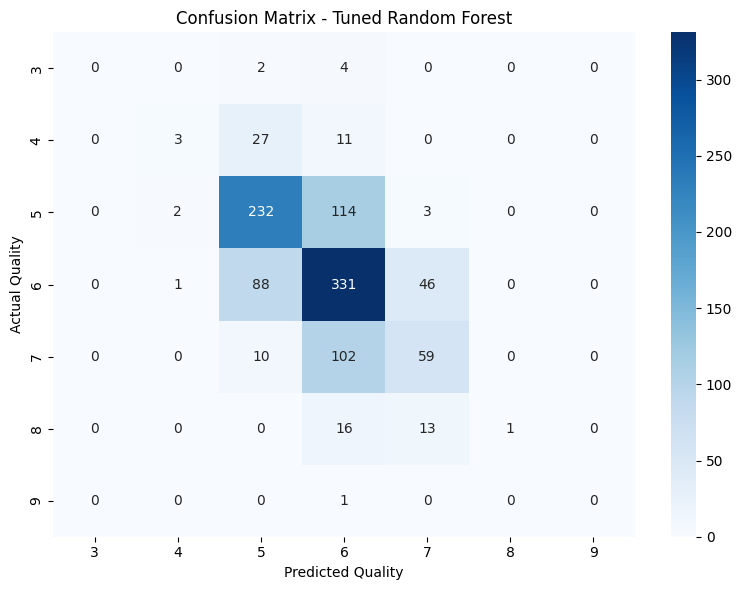

In [108]:
#Final Confusion Matrix
plt.figure(figsize=(8, 6))

cm = confusion_matrix(
    y_test,
    tuned_pred,
    labels=sorted(y.unique())
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.title("Confusion Matrix - Tuned Random Forest")
plt.xlabel("Predicted Quality")
plt.ylabel("Actual Quality")

plt.tight_layout()
plt.show()


In [109]:
# Model Saving
joblib.dump(
    tuned_model,
    "wine_quality_model.pkl"
)

['wine_quality_model.pkl']

In [110]:
joblib.dump(
    X.columns.tolist(),
    "wine_features.pkl"
)

['wine_features.pkl']